In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PV_DIR = Path("../data/raw/plantvillage/PlantVillage")

Matplotlib is building the font cache; this may take a moment.


In [2]:
class_dirs = sorted(d for d in PV_DIR.iterdir()
                    if d.is_dir() and d.name != "PlantVillage")
print(len(class_dirs))

15


In [3]:
rows = []
for d in class_dirs:
    count = sum(1 for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
    rows.append({"class": d.name, "count": count})

counts = pd.DataFrame(rows).sort_values("count")
print(counts)
print("Total:", counts["count"].sum())

                                          class  count
4                              Potato___healthy    152
13                  Tomato__Tomato_mosaic_virus    373
8                              Tomato_Leaf_Mold    952
0                 Pepper__bell___Bacterial_spot    997
2                         Potato___Early_blight   1000
3                          Potato___Late_blight   1000
6                           Tomato_Early_blight   1000
11                          Tomato__Target_Spot   1404
1                        Pepper__bell___healthy   1478
14                               Tomato_healthy   1591
10  Tomato_Spider_mites_Two_spotted_spider_mite   1676
9                     Tomato_Septoria_leaf_spot   1771
7                            Tomato_Late_blight   1909
5                         Tomato_Bacterial_spot   2127
12        Tomato__Tomato_YellowLeaf__Curl_Virus   3208
Total: 20638


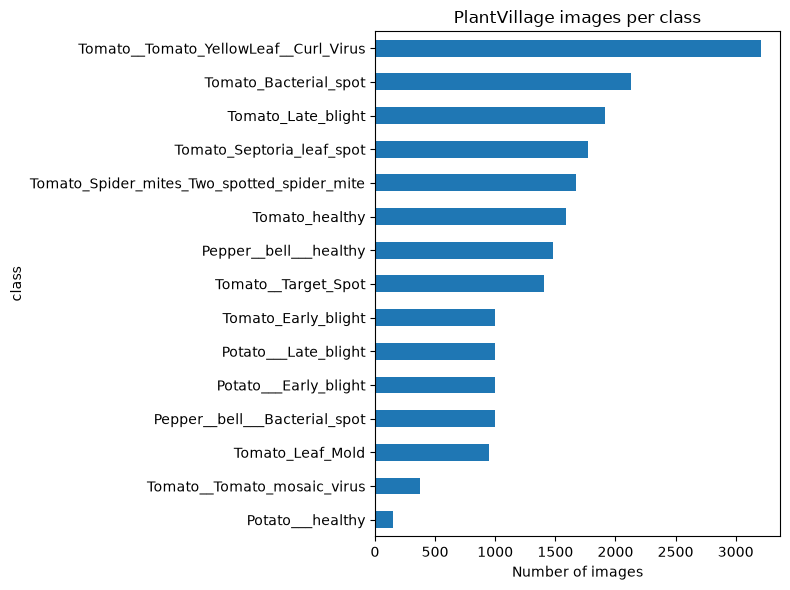

In [4]:
ax = counts.plot.barh(x="class", y="count", legend=False, figsize=(8, 6))
ax.set_xlabel("Number of images")
ax.set_title("PlantVillage images per class")
plt.tight_layout()
plt.savefig("../figures/class_counts.png", dpi=150)
plt.show()

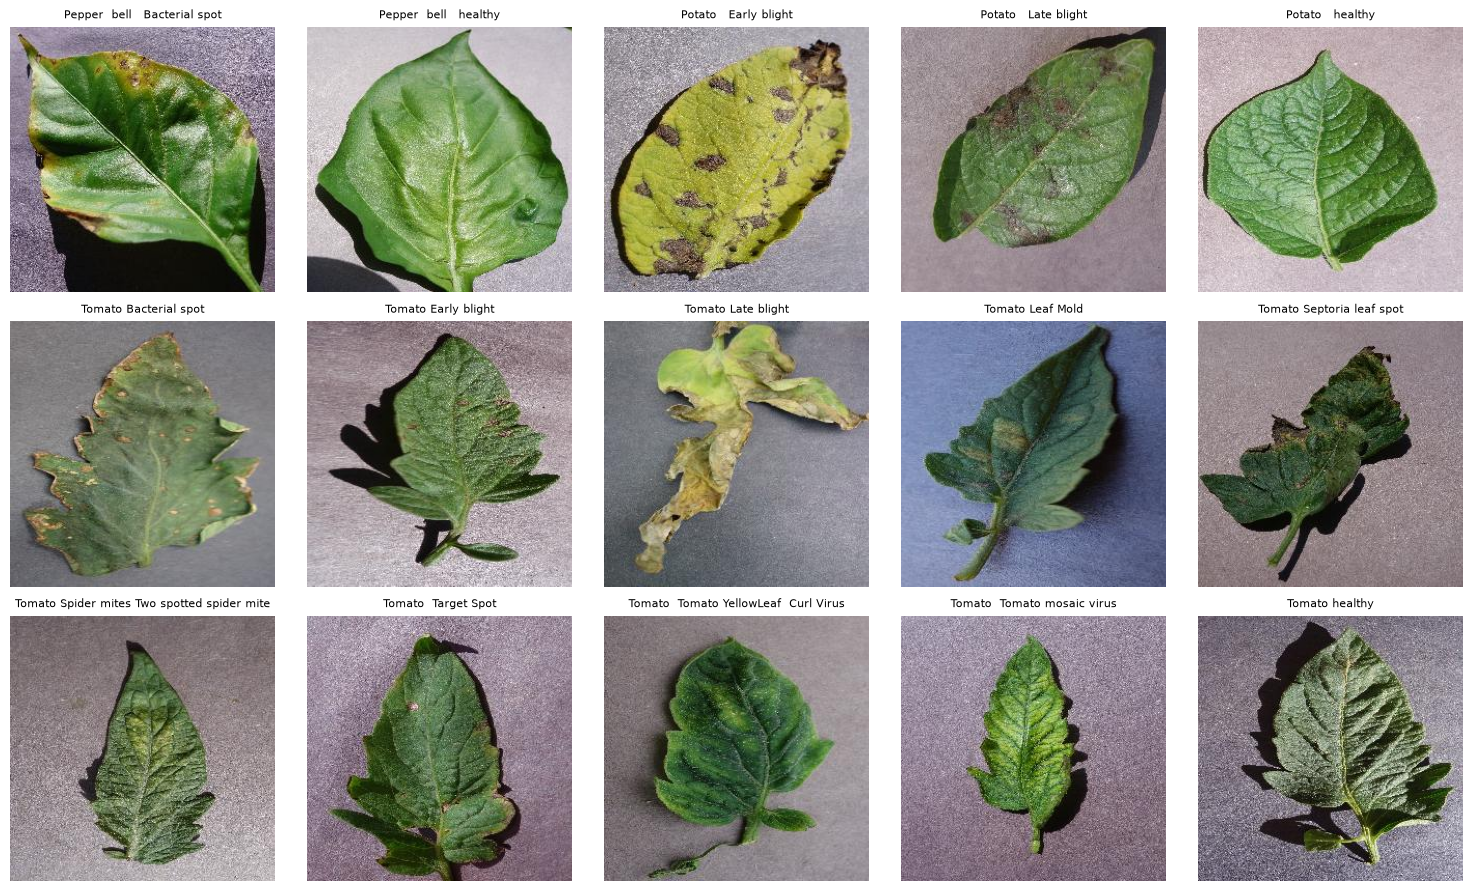

In [5]:
from PIL import Image

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, d in zip(axes.flat, class_dirs):
    first_image = next(f for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
    ax.imshow(Image.open(first_image))
    ax.set_title(d.name.replace("_", " "), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../figures/sample_grid.png", dpi=150)
plt.show()

In [6]:
from collections import Counter

sizes = Counter()
for d in class_dirs:
    for f in list(d.iterdir())[:50]:   # sample 50 per class to keep it fast
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            sizes[Image.open(f).size] += 1
print(sizes)

Counter({(256, 256): 750})


In [7]:
import hashlib

records, unreadable = [], []
for d in class_dirs:
    for f in d.iterdir():
        if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        try:
            with Image.open(f) as img:
                img.verify()          # checks the file isn't corrupt
        except Exception:
            unreadable.append(f)
            continue
        md5 = hashlib.md5(f.read_bytes()).hexdigest()   # fingerprint of the file's contents
        records.append({"path": str(f.relative_to(PV_DIR)), "label": d.name, "md5": md5})

df = pd.DataFrame(records)
print("Readable images:", len(df))
print("Unreadable:", len(unreadable))

Readable images: 20638
Unreadable: 0


In [8]:
dup_groups = df[df.duplicated("md5", keep=False)]
print("Images involved in duplicates:", len(dup_groups))

labels_per_hash = dup_groups.groupby("md5")["label"].nunique()
print("Duplicates with conflicting labels:", (labels_per_hash > 1).sum())

Images involved in duplicates: 28
Duplicates with conflicting labels: 0


In [9]:
conflicting = labels_per_hash[labels_per_hash > 1].index
clean = df[~df["md5"].isin(conflicting)].drop_duplicates("md5", keep="first")
print("Clean images:", len(clean))
print("Removed:", len(df) - len(clean))

Clean images: 20624
Removed: 14


In [10]:
from sklearn.model_selection import train_test_split

data = clean[["path", "label"]]

train, temp = train_test_split(data, test_size=0.30, stratify=data["label"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["label"], random_state=42)

print("Train:", len(train), " Val:", len(val), " Test:", len(test))

Train: 14436  Val: 3094  Test: 3094


In [11]:
check = pd.DataFrame({
    "train": train["label"].value_counts(),
    "val": val["label"].value_counts(),
    "test": test["label"].value_counts(),
})
print(check.sort_values("train"))

                                             train  val  test
label                                                        
Potato___healthy                               106   23    23
Tomato__Tomato_mosaic_virus                    261   56    56
Tomato_Leaf_Mold                               666  143   143
Pepper__bell___Bacterial_spot                  698  149   150
Potato___Early_blight                          700  150   150
Potato___Late_blight                           700  150   150
Tomato_Early_blight                            700  150   150
Tomato__Target_Spot                            983  210   211
Pepper__bell___healthy                        1035  222   221
Tomato_healthy                                1109  238   238
Tomato_Spider_mites_Two_spotted_spider_mite   1173  251   252
Tomato_Septoria_leaf_spot                     1240  266   265
Tomato_Late_blight                            1331  285   285
Tomato_Bacterial_spot                         1489  319   319
Tomato__

In [12]:
import json

SPLITS_DIR = Path("../splits")
SPLITS_DIR.mkdir(exist_ok=True)

train.to_csv(SPLITS_DIR / "train.csv", index=False)
val.to_csv(SPLITS_DIR / "val.csv", index=False)
test.to_csv(SPLITS_DIR / "test.csv", index=False)

class_names = sorted(data["label"].unique())
with open(SPLITS_DIR / "labels.json", "w") as f:
    json.dump(class_names, f, indent=2)
print(class_names)

['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [13]:
PD_DIR = Path("../data/raw/plantdoc")

pd_rows = []
for split in ["train", "test"]:
    for d in sorted((PD_DIR / split).iterdir()):
        if d.is_dir():
            n = sum(1 for f in d.iterdir() if f.suffix.lower() in {".jpg", ".jpeg", ".png"})
            pd_rows.append({"split": split, "folder": d.name, "count": n})

plantdoc_counts = pd.DataFrame(pd_rows)
print(plantdoc_counts.groupby("folder")["count"].sum().to_string())

folder
Apple Scab Leaf                          93
Apple leaf                               91
Apple rust leaf                          88
Bell_pepper leaf                         61
Bell_pepper leaf spot                    71
Blueberry leaf                          115
Cherry leaf                              57
Corn Gray leaf spot                      68
Corn leaf blight                        191
Corn rust leaf                          116
Peach leaf                              111
Potato leaf early blight                116
Potato leaf late blight                 105
Raspberry leaf                          119
Soyabean leaf                            65
Squash Powdery mildew leaf              130
Strawberry leaf                          96
Tomato Early blight leaf                 88
Tomato Septoria leaf spot               151
Tomato leaf                              63
Tomato leaf bacterial spot              110
Tomato leaf late blight                 111
Tomato leaf mosaic virus 

In [14]:
PLANTDOC_TO_PV = {
    "Bell_pepper leaf":            "Pepper__bell___healthy",
    "Bell_pepper leaf spot":       "Pepper__bell___Bacterial_spot",
    "Potato leaf early blight":    "Potato___Early_blight",
    "Potato leaf late blight":     "Potato___Late_blight",
    "Tomato leaf":                 "Tomato_healthy",
    "Tomato Early blight leaf":    "Tomato_Early_blight",
    "Tomato leaf late blight":     "Tomato_Late_blight",
    "Tomato leaf bacterial spot":  "Tomato_Bacterial_spot",
    "Tomato mold leaf":            "Tomato_Leaf_Mold",
    "Tomato Septoria leaf spot":   "Tomato_Septoria_leaf_spot",
    "Tomato leaf mosaic virus":    "Tomato__Tomato_mosaic_virus",
    "Tomato leaf yellow virus":    "Tomato__Tomato_YellowLeaf__Curl_Virus",
}

field_records, field_unreadable = [], []
for split in ["train", "test"]:
    for folder, label in PLANTDOC_TO_PV.items():
        d = PD_DIR / split / folder
        if not d.exists():
            continue
        for f in d.iterdir():
            if f.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            try:
                with Image.open(f) as img:
                    img.verify()
            except Exception:
                field_unreadable.append(f)
                continue
            md5 = hashlib.md5(f.read_bytes()).hexdigest()
            field_records.append({"path": str(f.relative_to(PD_DIR)), "label": label, "md5": md5})

field = pd.DataFrame(field_records)
print("Field images:", len(field), " Unreadable:", len(field_unreadable))

Field images: 1097  Unreadable: 0


In [15]:
# Duplicates within PlantDoc
field = field.drop_duplicates("md5", keep="first")

# Images that also appear in PlantVillage (would mean the model has seen them)
overlap = field["md5"].isin(clean["md5"])
print("Overlap with PlantVillage:", overlap.sum())
field = field[~overlap]

print("Final field images:", len(field))
print(field["label"].value_counts().to_string())

field[["path", "label"]].to_csv(SPLITS_DIR / "field_test.csv", index=False)

Overlap with PlantVillage: 0
Final field images: 1089
label
Tomato_Septoria_leaf_spot                150
Potato___Early_blight                    115
Tomato_Late_blight                       111
Tomato_Bacterial_spot                    109
Potato___Late_blight                     101
Tomato_Leaf_Mold                          91
Tomato_Early_blight                       88
Tomato__Tomato_YellowLeaf__Curl_Virus     75
Pepper__bell___Bacterial_spot             71
Tomato_healthy                            63
Pepper__bell___healthy                    61
Tomato__Tomato_mosaic_virus               54
